# 🏔️ Fine-tuning a Geospatial Foundation Model for Landslide Detection

## Part 1 — Fine-tuning Prithvi-EO-2.0 on Landslide4Sense with TerraTorch

**Task:** binary semantic segmentation — classify every pixel of a satellite image patch as *landslide* or *non-landslide*.

---

### Presenters

- **Presenter Name** — Affiliation
- **Presenter Name** — Affiliation

---

### Learning objectives

By the end of this session you will be able to:

1. Explain what a **geospatial foundation model (GFM)** is and how Prithvi-EO-2.0 was pretrained.
2. Load and explore the **Landslide4Sense** benchmark dataset (14-band HDF5 patches).
3. Map a new sensor's bands onto the bands a foundation model was **pretrained** on, and understand why that mapping matters.
4. Read and modify a **TerraTorch** experiment configuration (backbone, necks, decoder, loss, optimizer, metrics).
5. **Fine-tune** Prithvi on a single GPU, monitor training curves, and evaluate the result.
6. Name the main **"knobs"** that control fine-tuning behavior and their expected effects.

### Estimated duration: ~1.5 hours

| # | Section | Time |
|---|---------|------|
| 1 | Environment setup | 10 min |
| 2 | Geospatial foundation models & Prithvi | 10 min |
| 3 | Landslide4Sense: download & exploration | 20 min |
| 4 | From 14 bands to 6: preparing inputs for Prithvi | 10 min |
| 5 | TerraTorch configuration walkthrough | 10 min |
| 6 | Fine-tuning run | 25 min |
| 7 | Training curves & validation results | 10 min |
| 8 | Knobs to turn & wrap-up | 5 min |

> 💡 **How to read this notebook.** Every code cell is preceded by a markdown cell explaining *what* it does and *why*. If you are a remote-sensing scientist new to deep learning, focus on the markdown; if you are an ML practitioner new to Earth observation, the EO-specific notes are for you.


---
## Section 1. Environment setup *(≈10 min)*

### 🎯 Objective
Install TerraTorch and verify we have a working GPU.

**What is TerraTorch?** [TerraTorch](https://github.com/IBM/terratorch) is IBM's fine-tuning toolkit for geospatial foundation models, built on [PyTorch Lightning](https://lightning.ai/docs/pytorch/stable/) and [TorchGeo](https://torchgeo.readthedocs.io/). It ships ready-made Prithvi backbones, segmentation/regression "tasks", and datamodules for common EO benchmarks — including Landslide4Sense — so we can fine-tune with configuration rather than hand-rolled training loops.

The cell below installs a pinned version of TerraTorch (which pulls in PyTorch, Lightning, TorchGeo, albumentations, etc.). On a fresh cloud GPU environment this takes a few minutes.

> ⚠️ **Colab note:** if pip reports dependency conflicts or asks you to restart, use *Runtime → Restart session* once after the install finishes, then re-run from the imports cell below.


In [1]:
# Install TerraTorch (pinned to the version this notebook was verified with).
# The -q flag keeps pip's output short; remove it if you want to watch progress.
%pip install -q "terratorch==1.2.11"


Note: you may need to restart the kernel to use updated packages.


Now we import everything we need and run two sanity checks:

1. **Library versions** — deep-learning stacks move fast; printing versions makes the notebook reproducible and makes debugging in a workshop room much easier.
2. **Device detection** — the code is device-agnostic: it uses an NVIDIA GPU (`cuda`) if present, Apple Silicon (`mps`) as a fallback, otherwise CPU. Fine-tuning a 300M-parameter model **really wants a GPU**; on CPU only a tiny smoke test is realistic.

We also **set random seeds** (Python, NumPy, PyTorch) via Lightning's `seed_everything` so runs are repeatable. Note that some GPU kernels (and multi-worker data loading order) are still non-deterministic, so your loss curves may differ slightly from the ones embedded here — that is expected.


In [2]:
import os
import importlib.metadata as im
from pathlib import Path

import h5py                      # reads the dataset's HDF5 patch files
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import lightning.pytorch as pl   # training loop engine underneath TerraTorch
import terratorch                # geospatial fine-tuning toolkit (registers Prithvi backbones on import)

# --- versions: helps everyone in the room debug from the same baseline ---
for pkg in ["terratorch", "torch", "lightning", "torchgeo", "albumentations", "h5py", "numpy"]:
    print(f"{pkg:>15s}  {im.version(pkg)}")

# --- device detection: cuda > mps > cpu ---
if torch.cuda.is_available():
    DEVICE = "cuda"
    print("\nGPU:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    DEVICE = "mps"
    print("\nUsing Apple Silicon (MPS) — expect slower training than a CUDA GPU.")
else:
    DEVICE = "cpu"
    print("\nNo GPU detected — fine-tuning will be very slow; use NUM_EPOCHS=2 as a smoke test only.")

# --- reproducibility: seeds Python, NumPy and PyTorch (CPU + CUDA) ---
SEED = 42
pl.seed_everything(SEED, workers=True)


Seed set to 42


     terratorch  1.2.11
          torch  2.15.0
      lightning  2.6.6
       torchgeo  0.8.1
 albumentations  2.0.8
           h5py  3.16.0
          numpy  2.4.6

GPU: NVIDIA A100-SXM4-40GB


42

Finally, we define the folder layout. The notebook assumes it runs **from the workshop folder root** (the folder containing `configs/`), and creates:

- `data/` — the Landslide4Sense download (~2 GB)
- `checkpoints/` — fine-tuned model weights
- `outputs/` — figures and training logs

If you run it from somewhere else, just set `BASE_DIR` accordingly.


In [3]:
BASE_DIR = Path.cwd()                       # change me if you run the notebook from elsewhere
DATA_DIR = BASE_DIR / "data" / "Landslide4sense"
CKPT_DIR = BASE_DIR / "checkpoints"
OUT_DIR  = BASE_DIR / "outputs"
for d in (DATA_DIR, CKPT_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Workshop folder:", BASE_DIR)


Workshop folder: /media/volume/data_2T/bdec_pipeline/prithvi-landslide-workshop


---
## Section 2. Geospatial foundation models & Prithvi *(≈10 min)*

### 🎯 Objective
Understand what we are fine-tuning, and why starting from a foundation model beats training from scratch.

### What is a geospatial foundation model?

A **foundation model** is a large neural network pretrained on huge amounts of *unlabeled* data with a self-supervised objective, then adapted ("fine-tuned") to many downstream tasks with comparatively little labeled data. In computer vision the classic recipe is the **masked autoencoder (MAE)**: hide a large fraction of the image patches, and train a Vision Transformer (ViT) to reconstruct them. To solve that task well, the encoder must learn what land surfaces look like — texture, spectra, context — without ever seeing a label.

**Why this matters for Earth observation:** labels are the bottleneck in EO. Global imagery is petabyte-scale and free; expert-annotated masks (like landslide inventories) are tiny and expensive. A foundation model moves most of the learning onto the unlabeled imagery, so a few thousand labeled patches — exactly what Landslide4Sense gives us — can produce a strong model.

### Prithvi-EO-2.0 in one paragraph

[**Prithvi-EO-2.0**](https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M) is a family of ViT-based geospatial foundation models developed by **IBM and NASA**, pretrained with a masked-autoencoder objective on global time series of **Harmonized Landsat–Sentinel-2 (HLS)** imagery at 30 m resolution. The pretraining used **6 spectral bands** (Blue, Green, Red, Narrow NIR, SWIR-1, SWIR-2) and added temporal and location embeddings. We use the **300M-parameter** variant: large enough to show the foundation-model benefit, small enough to fine-tune on a single GPU in a workshop.

### Why landslides are a good test case

Landslide mapping after a triggering event (earthquake, extreme rainfall) is time-critical, labels are scarce, and the visual signature — fresh soil scars in vegetated terrain — mixes spectral and textural cues. That is exactly the regime where transferring pretrained representations helps.

*No code in this section — take a breath before the data arrives.* ☕


---
## Section 3. Landslide4Sense: download & exploration *(≈20 min)*

### 🎯 Objective
Download the dataset, understand its structure, and look at actual landslides.

### The Landslide4Sense dataset

[Landslide4Sense](https://huggingface.co/datasets/ibm-nasa-geospatial/Landslide4sense) (Ghorbanzadeh et al., IEEE TGRS 2022) is a globally distributed benchmark for landslide detection, built from imagery around landslide events. Each sample is a **128 × 128 pixel patch at ~10 m resolution** with **14 channels**:

| Channels | Source | Content |
|----------|--------|---------|
| 1–12 | Sentinel-2 | Multispectral bands B1–B12 |
| 13 | ALOS PALSAR | Slope |
| 14 | ALOS PALSAR | Digital elevation model (DEM) |

and a pixel-wise binary mask (`1` = landslide). The splits are **train 3799 / validation 245 / test 800** patches.

The cell below downloads the dataset from Hugging Face (~9,700 small HDF5 files, ~2 GB). To make re-runs instant, we first check whether the files are already on disk and skip the download if so.


In [4]:
from huggingface_hub import snapshot_download

def l4s_present(root: Path) -> bool:
    """Cheap completeness check: count HDF5 files instead of re-querying the Hub."""
    n = sum(1 for _ in root.glob("*/*/*.h5")) if root.exists() else 0
    return n >= 9688   # 4844 images + 4844 masks across the three splits

if l4s_present(DATA_DIR):
    print("Dataset already on disk — skipping download.")
else:
    snapshot_download(
        "ibm-nasa-geospatial/Landslide4sense",
        repo_type="dataset",
        local_dir=DATA_DIR,       # materialize files under data/Landslide4sense/
    )
print("images:", sum(1 for _ in (DATA_DIR / "images").glob("*/*.h5")),
      "| masks:", sum(1 for _ in (DATA_DIR / "annotations").glob("*/*.h5")))


Dataset already on disk — skipping download.
images: 4844 | masks: 4849


### Inside one HDF5 file

Each image file holds a single dataset named `img` with shape `(128, 128, 14)` (height × width × channels), and each mask file holds `mask` with shape `(128, 128)`. Let's open one of each and confirm — **never trust a dataset README without checking the arrays**. We also print per-band statistics: note that the values are *already standardized* by the dataset creators (roughly zero-centered, unit-ish spread) rather than raw reflectances.


In [5]:
BAND_NAMES = [  # the 14 channels, in storage order
    "B1 Coastal aerosol", "B2 Blue", "B3 Green", "B4 Red",
    "B5 Red edge 1", "B6 Red edge 2", "B7 Red edge 3", "B8 NIR (broad)",
    "B9 Water vapour", "B10 Cirrus", "B11 SWIR-1", "B12 SWIR-2",
    "B13 Slope", "B14 DEM",
]

with h5py.File(DATA_DIR / "images" / "train" / "image_10.h5") as f:
    img = np.array(f["img"])                    # (128, 128, 14) float
with h5py.File(DATA_DIR / "annotations" / "train" / "mask_10.h5") as f:
    mask = np.array(f["mask"])                  # (128, 128) int, 0/1

print("image:", img.shape, img.dtype, "| mask:", mask.shape, mask.dtype,
      "| mask values:", np.unique(mask))
print(f"\n{'band':<22s}{'min':>9s}{'mean':>9s}{'max':>9s}")
for i, name in enumerate(BAND_NAMES):
    b = img[:, :, i]
    print(f"{name:<22s}{b.min():>9.3f}{b.mean():>9.3f}{b.max():>9.3f}")


image: (128, 128, 14) float64 | mask: (128, 128) uint8 | mask values: [0]

band                        min     mean      max
B1 Coastal aerosol        0.934    0.976    1.046
B2 Blue                   0.891    0.992    1.335
B3 Green                  0.803    1.072    1.643
B4 Red                    0.759    1.074    2.482
B5 Red edge 1             0.681    1.218    2.166
B6 Red edge 2             0.574    1.231    1.814
B7 Red edge 3             0.552    1.233    1.789
B8 NIR (broad)            0.446    1.259    1.942
B9 Water vapour           0.930    1.523    2.086
B10 Cirrus                1.216    1.561    1.879
B11 SWIR-1                0.450    1.316    2.603
B12 SWIR-2                0.419    1.259    3.660
B13 Slope                 0.000    1.340    3.450
B14 DEM                   1.488    1.934    2.294


### Label distribution: how rare are landslide pixels?

Class imbalance drives many design choices (loss function, metrics). We scan every **training** mask and compute:

- the fraction of *pixels* that are landslide,
- the fraction of *patches* that contain at least one landslide pixel.

This takes a few seconds (3,799 small files).


train patches:                  3799
landslide pixel fraction:       2.32%
patches containing a landslide: 2231 (58.7%)


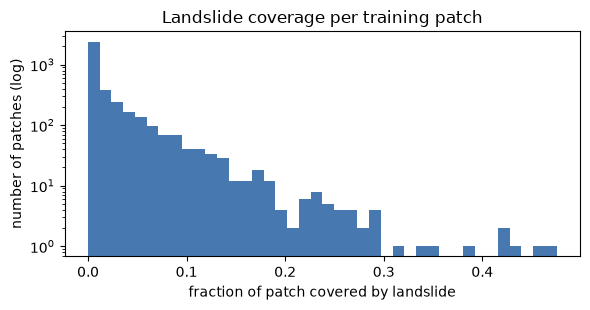

In [6]:
train_masks = sorted((DATA_DIR / "annotations" / "train").glob("mask_*.h5"))

landslide_px, total_px, patches_with_ls, per_patch_frac = 0, 0, 0, []
for mf in train_masks:
    with h5py.File(mf) as f:
        m = np.array(f["mask"])
    s = int(m.sum())
    landslide_px += s
    total_px += m.size
    patches_with_ls += s > 0
    per_patch_frac.append(s / m.size)

print(f"train patches:                  {len(train_masks)}")
print(f"landslide pixel fraction:       {landslide_px / total_px:.2%}")
print(f"patches containing a landslide: {patches_with_ls} ({patches_with_ls / len(train_masks):.1%})")

# Histogram of per-patch landslide coverage (log scale: most patches are empty or nearly so)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(per_patch_frac, bins=40, color="#4878b0")
ax.set_yscale("log")
ax.set_xlabel("fraction of patch covered by landslide")
ax.set_ylabel("number of patches (log)")
ax.set_title("Landslide coverage per training patch")
fig.tight_layout()
fig.savefig(OUT_DIR / "label_distribution.png", dpi=120)
plt.show()


**Takeaway:** landslide pixels are a small minority — this is a heavily **imbalanced** segmentation problem. Plain pixel accuracy would look great for a model that predicts "no landslide" everywhere, which is why we will track **IoU (Jaccard index)** and **F1** instead, and train with a **Dice loss** that is robust to imbalance.

### Visualizing sample patches

Let's look at a few patches that do contain landslides: a true-color RGB composite (bands B4/B3/B2), the label mask, and the mask overlaid on the RGB. Because the band values are standardized (not reflectance), we stretch each band to the 2nd–98th percentile for display — a standard remote-sensing visualization trick.


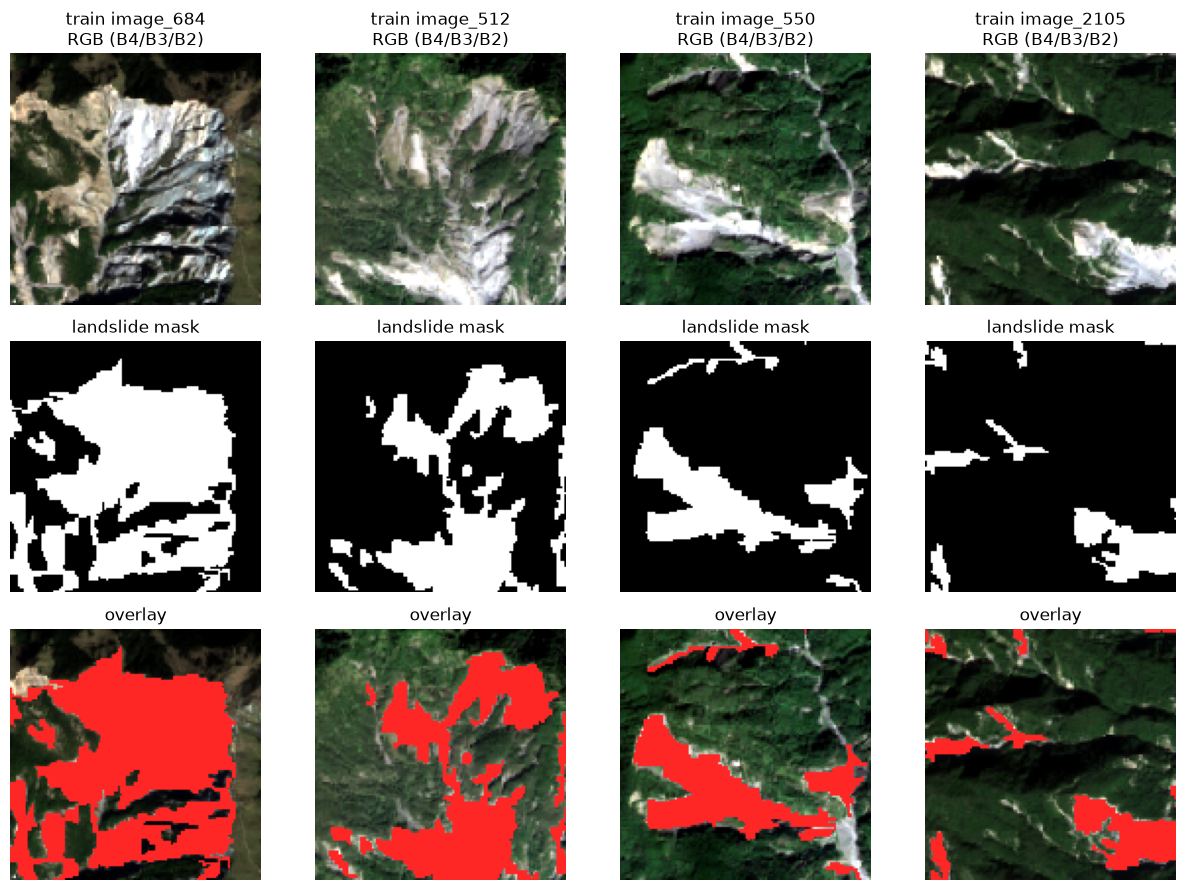

In [7]:
def rgb_composite(img14: np.ndarray) -> np.ndarray:
    """True-color composite from a (H, W, 14) patch, percentile-stretched for display."""
    rgb = img14[:, :, [3, 2, 1]]                       # B4 Red, B3 Green, B2 Blue
    lo, hi = np.percentile(rgb, (2, 98), axis=(0, 1))  # per-band 2–98% stretch
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

def load_sample(split: str, idx: int):
    with h5py.File(DATA_DIR / "images" / split / f"image_{idx}.h5") as f:
        img = np.array(f["img"])
    with h5py.File(DATA_DIR / "annotations" / split / f"mask_{idx}.h5") as f:
        mask = np.array(f["mask"])
    return img, mask

# a few training patches with substantial landslide coverage
show_ids = [int(train_masks[i].stem.split("_")[1])
            for i in np.argsort(per_patch_frac)[::-1][[0, 10, 50, 200]]]

fig, axes = plt.subplots(3, len(show_ids), figsize=(3.1 * len(show_ids), 9.0))
for col, idx in enumerate(show_ids):
    img, m = load_sample("train", idx)
    rgb = rgb_composite(img)
    axes[0, col].imshow(rgb);            axes[0, col].set_title(f"train image_{idx}\nRGB (B4/B3/B2)")
    axes[1, col].imshow(m, cmap="gray"); axes[1, col].set_title("landslide mask")
    over = rgb.copy(); over[m == 1] = [1.0, 0.15, 0.15]   # paint landslide pixels red
    axes[2, col].imshow(over);           axes[2, col].set_title("overlay")
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT_DIR / "sample_patches.png", dpi=120)
plt.show()


---
## Section 4. From 14 bands to 6: preparing inputs for Prithvi *(≈10 min)*

### 🎯 Objective
Understand exactly how Landslide4Sense's channels map onto what Prithvi was pretrained on — the most important (and most often botched) step when reusing a foundation model on a new dataset.

### What Prithvi expects

Prithvi-EO-2.0 was pretrained on **HLS** imagery with exactly these 6 bands, in this order:

| Prithvi band | HLS source | Landslide4Sense equivalent | Match quality |
|--------------|-----------|---------------------------|---------------|
| BLUE | S2 B02 / Landsat B2 | channel 2 (B2 Blue) | ✅ exact |
| GREEN | S2 B03 / Landsat B3 | channel 3 (B3 Green) | ✅ exact |
| RED | S2 B04 / Landsat B4 | channel 4 (B4 Red) | ✅ exact |
| NIR_NARROW | S2 **B8A** (865 nm, narrow) | channel 8 (**B8** broad NIR, 842 nm) | ⚠️ close substitute |
| SWIR_1 | S2 B11 | channel 11 (B11 SWIR-1) | ✅ exact |
| SWIR_2 | S2 B12 | channel 12 (B12 SWIR-2) | ✅ exact |

Three things to notice:

1. **We drop 8 channels.** Coastal aerosol, red edge, water vapour and cirrus bands were never seen during pretraining, so the pretrained patch-embedding has no weights for them. (Extending the input layer to extra channels *is* possible — see "knobs to turn".)
2. **The NIR substitution.** Landslide4Sense ships Sentinel-2's *broad* NIR (B8) but not the *narrow* B8A that HLS uses. The two bands overlap heavily (B8 spans ~785–900 nm; B8A sits inside it at ~855–875 nm), so we feed B8 into the `NIR_NARROW` slot. This is a pragmatic, well-matched substitution — but it is a *choice*, and you should always document choices like this.
3. **Slope and DEM are discarded**, even though topography is extremely informative for landslides. That is the price of using a spectral-only foundation model out of the box — and a great discussion point for your own research.

### Patching and normalization

Internally, Prithvi is a **Vision Transformer**: the 128×128×6 input is cut into **16×16 patch tokens** (an 8×8 grid = 64 tokens), each linearly embedded into a 1024-dimensional vector that flows through 24 transformer layers. Before that, inputs must be **normalized per band** (zero mean, unit variance). TerraTorch's Landslide4Sense datamodule ships dataset-wide band statistics and applies this normalization for us — one less thing to get wrong.

### Data augmentation

We also add light **geometric augmentation** to the training split: random horizontal/vertical flips and 90° rotations. Landslides have no canonical orientation, so these transforms are label-preserving "free" extra data — with only 3,799 training patches against a 300M-parameter model, this is our main defense against overfitting. Augmentation applies to *training only*; validation and test stay untouched so the metrics remain comparable.

TerraTorch's datamodule takes a `bands=[...]` argument and does the channel selection *by name*, which keeps the band mapping explicit and auditable:


In [8]:
import albumentations as A                      # EO-friendly augmentation library
from albumentations.pytorch import ToTensorV2
from terratorch.datamodules import Landslide4SenseNonGeoDataModule
from terratorch.datamodules.landslide4sense import MEANS, STDS   # dataset-wide band stats

# Channel selection BY NAME — this is the entire "14 bands -> 6 bands" step.
BANDS = ["BLUE", "GREEN", "RED", "NIR_BROAD", "SWIR_1", "SWIR_2"]

# Geometric augmentation (training split only): orientation carries no label
# information for landslides, so flips/rotations are safe.
train_transform = [
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    ToTensorV2(),            # keep last: converts numpy HWC -> torch CHW
]

BATCH_SIZE = 16
datamodule = Landslide4SenseNonGeoDataModule(
    data_root=str(DATA_DIR),
    bands=BANDS,
    batch_size=BATCH_SIZE,
    num_workers=4,          # parallel HDF5 readers; set 0 if your platform complains
    train_transform=train_transform,
)
datamodule.setup("fit")     # instantiates the train/val datasets

print("train / val samples:", len(datamodule.train_dataset), "/", len(datamodule.val_dataset))
print("normalization means:", [round(MEANS[b], 3) for b in BANDS])
print("normalization stds: ", [round(STDS[b], 3) for b in BANDS])

batch = next(iter(datamodule.train_dataloader()))
print("\nbatch image tensor:", tuple(batch["image"].shape), batch["image"].dtype)
print("batch mask tensor: ", tuple(batch["mask"].shape), batch["mask"].dtype)


train / val samples: 3799 / 245
normalization means: [-0.307, -0.128, -0.062, 0.08, 0.082, 0.052]
normalization stds:  [0.877, 0.886, 0.887, 0.849, 0.885, 0.923]



batch image tensor: (16, 6, 128, 128) torch.float32
batch mask tensor:  (16, 128, 128) torch.int64


The batch is `(batch, 6 channels, 128, 128)` images with `(batch, 128, 128)` integer masks — exactly what a segmentation model wants. Note the normalization is applied *on the GPU per batch* (inside the datamodule's augmentation pipeline), so the tensors you see here are still un-normalized; we will reuse `MEANS`/`STDS` in Part 2 when we run inference manually.


---
## Section 5. TerraTorch configuration walkthrough *(≈10 min)*

### 🎯 Objective
Read a complete TerraTorch experiment config and understand every block.

TerraTorch experiments are usually driven by a single **YAML file** — run `terratorch fit --config <file>` and you get the whole pipeline with no notebook at all. The file `configs/prithvi_eo_v2_300_landslide4sense.yaml` in this folder is the exact config for today's experiment. Let's print it, then dissect the blocks.


In [9]:
print((BASE_DIR / "configs" / "prithvi_eo_v2_300_landslide4sense.yaml").read_text())


# TerraTorch config — Prithvi-EO-2.0-300M fine-tuning on Landslide4Sense
# Binary semantic segmentation (landslide / non-landslide), 128x128 HDF5 patches.
#
# Run from the workshop folder with:
#   terratorch fit --config configs/prithvi_eo_v2_300_landslide4sense.yaml
# or load it inside the notebooks (Part 1 walks through every block).

seed_everything: 42

# ---------------------------------------------------------------------------
# Trainer: standard PyTorch Lightning trainer settings
# ---------------------------------------------------------------------------
trainer:
  accelerator: auto            # picks cuda > mps > cpu automatically
  strategy: auto
  devices: auto
  precision: 16-mixed          # mixed precision: ~2x faster on modern GPUs
  max_epochs: 30               # reduce to 2 for a quick smoke test
  log_every_n_steps: 10
  logger:
    class_path: lightning.pytorch.loggers.CSVLogger   # simple, file-based; easy to plot from
    init_args:
      save_dir: outputs/logs


### Block-by-block

**`trainer:`** — plain PyTorch Lightning. `precision: 16-mixed` runs most math in float16 (≈2× faster, half the memory) while keeping master weights in float32. `CSVLogger` writes metrics to a plain CSV we can plot with pandas. `ModelCheckpoint` keeps the epoch with the best **validation IoU** plus the last epoch.

**`data:`** — the datamodule we just built, as configuration. Note `bands:` — the band mapping from Section 4 lives *in the config*, where reviewers can see it.

**`model:` → `model_args:`** — this is the TerraTorch-specific part, assembled by the `EncoderDecoderFactory`:

- **`backbone: prithvi_eo_v2_300`** — the pretrained 300M-parameter Prithvi ViT encoder; `backbone_pretrained: true` downloads the IBM/NASA weights. `backbone_bands` tells the model *which pretrained band embeddings* to use for the 6 incoming channels (our B8 data enters through the `NIR_NARROW` embedding).
- **`necks:`** — adapters between a ViT and a conv decoder. A ViT outputs a flat sequence of 64 tokens per layer, but a UNet-style decoder wants a *pyramid* of 2-D feature maps. `SelectIndices` taps transformer layers 6/12/18/24, `ReshapeTokensToImage` folds each token sequence back into an 8×8 grid, and `LearnedInterpolateToPyramidal` upsamples them to the multi-resolution pyramid the decoder expects.
- **`decoder: UNetDecoder`** — a lightweight convolutional decoder (~20M params) that fuses the pyramid and predicts a 2-class logit map at full 128×128 resolution.

**`loss: dice`** — Dice loss optimizes overlap directly and is far more robust to the ~2% positive-pixel imbalance than cross-entropy alone.

**`optimizer / scheduler`** — AdamW at `lr 3e-5` with weight decay 0.05, cosine-annealed over the run: a boring, reliable recipe for ViT fine-tuning. The one rule: fine-tuning a pretrained backbone wants a learning rate 10–100× *smaller* than training from scratch, so the pretrained weights are nudged, not bulldozed. (At `1e-4` this run reaches its best validation mIoU within ~3 epochs and then overfits; `3e-5` trades a slower start for a steadier, slightly better optimum — try both.)

**Metrics** come built into TerraTorch's `SemanticSegmentationTask`: mean **IoU (Jaccard)**, **F1**, and pixel accuracy, logged every validation epoch.

**`freeze_backbone: false`** — we fine-tune *end-to-end*. Flip it to `true` and only the decoder trains (see Section 8).


---
## Section 6. Fine-tuning run *(≈25 min)*

### 🎯 Objective
Fine-tune Prithvi on Landslide4Sense and watch it learn.

Below we build the same experiment **in Python** (so you can see the objects behind the YAML): a `SemanticSegmentationTask` wrapping the Prithvi encoder + UNet decoder, then a Lightning `Trainer`.

**Runtime expectations:** on a single A100 GPU, one epoch (238 training steps at batch 16, plus validation) takes well under a minute — the full 30-epoch run finishes in roughly 20–30 minutes. On a smaller GPU (e.g., Colab T4), expect a few minutes per epoch; consider `NUM_EPOCHS = 10`. On CPU, set `NUM_EPOCHS = 2` and treat it purely as a smoke test.


In [10]:
from terratorch.tasks import SemanticSegmentationTask

NUM_EPOCHS = 30   # reduce to 2 for a quick smoke test
LR = 3e-5

task = SemanticSegmentationTask(
    model_factory="EncoderDecoderFactory",
    model_args=dict(
        # --- encoder: pretrained Prithvi-EO-2.0, 300M parameters ---
        backbone="prithvi_eo_v2_300",
        backbone_pretrained=True,
        backbone_bands=["BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2"],
        # --- necks: ViT token sequences -> conv feature pyramid ---
        necks=[
            {"name": "SelectIndices", "indices": [5, 11, 17, 23]},  # tap layers 6/12/18/24
            {"name": "ReshapeTokensToImage"},
            {"name": "LearnedInterpolateToPyramidal"},
        ],
        # --- decoder: UNet-style convolutional decoder ---
        decoder="UNetDecoder",
        decoder_channels=[512, 256, 128, 64],
        num_classes=2,
        head_dropout=0.1,
    ),
    loss="dice",                               # overlap-based loss, robust to class imbalance
    lr=LR,
    optimizer="AdamW",
    optimizer_hparams={"weight_decay": 0.05},
    scheduler="CosineAnnealingLR",
    scheduler_hparams={"T_max": NUM_EPOCHS},   # decay the LR to ~0 over the whole run
    freeze_backbone=False,                     # True = train decoder only (faster, lower IoU)
)
n_params = sum(p.numel() for p in task.model.parameters())
print(f"model parameters: {n_params/1e6:.1f}M")


model parameters: 324.2M


Now the `Trainer`. Two callbacks matter:

- **`ModelCheckpoint`** saves the weights whenever validation mean IoU improves (→ `checkpoints/`, used again in Part 2) and also saves `last.ckpt`.
- **`CSVLogger`** writes every logged metric to `outputs/logs/.../metrics.csv` for plotting afterwards.

Then we call `trainer.fit(...)` — Lightning runs the full loop (forward, loss, backward, optimizer step, validation each epoch). This is the long cell: start it, stretch your legs, and watch the per-epoch validation IoU climb. ☕


In [11]:
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor
from lightning.pytorch.loggers import CSVLogger

checkpoint_cb = ModelCheckpoint(
    dirpath=CKPT_DIR,
    filename="prithvi300-landslide-{epoch:02d}",
    monitor="val/mIoU",                       # mean IoU on the validation split
    mode="max",
    save_top_k=1,
    save_last=True,
)

trainer = pl.Trainer(
    accelerator="auto", devices=1,                 # cuda / mps / cpu, whatever is available
    precision="16-mixed" if DEVICE == "cuda" else "32-true",
    max_epochs=NUM_EPOCHS,
    logger=CSVLogger(save_dir=OUT_DIR / "logs", name="prithvi_landslide"),
    callbacks=[checkpoint_cb, LearningRateMonitor(logging_interval="epoch")],
    log_every_n_steps=10,
    enable_progress_bar=False,   # keep the saved notebook readable; set True when presenting live
)

trainer.fit(task, datamodule=datamodule)

print("\nbest checkpoint:", checkpoint_cb.best_model_path)
print(f"best val mIoU:   {checkpoint_cb.best_model_score:.4f}")


Using 16bit Automatic Mixed Precision (AMP)


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


/home/exouser/miniconda3/envs/landslide/lib/python3.11/site-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


... (2 outputs left out)

/home/exouser/miniconda3/envs/landslide/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


/home/exouser/miniconda3/envs/landslide/lib/python3.11/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)


`Trainer.fit` stopped: `max_epochs=30` reached.



best checkpoint: /media/volume/data_2T/bdec_pipeline/prithvi-landslide-workshop/checkpoints/prithvi300-landslide-epoch=17.ckpt
best val mIoU:   0.6781


---
## Section 7. Training curves & validation results *(≈10 min)*

### 🎯 Objective
Diagnose the run from its logs, then look at predictions with your own eyes.

### Training curves

The CSV logger wrote one row per logging step. We aggregate per epoch and plot (left) train vs. validation **loss** and (right) validation **mean IoU**, **landslide-class IoU**, and **F1**. Read these curves honestly — they show two things you will meet constantly in practice:

- **Fast adaptation, then overfitting.** Validation improvement is front-loaded: most of the gain arrives in the first third of the run, after which validation metrics plateau (the best epoch lands wherever noise peaks on that plateau) while train loss keeps falling — memorization setting in — with 3,799 training patches against 324M parameters, the model starts memorizing despite the augmentation. This is *exactly* why we checkpoint on best validation mIoU instead of keeping the last epoch. (At a hotter learning rate like `1e-4`, the peak arrives by epoch 2–3 and the decline is steeper — try it.)
- **Noisy validation metrics.** The validation split has only 245 patches and few landslide pixels, so per-epoch landslide IoU swings hard. Don't over-interpret single-epoch wiggles on small EO validation sets; look at the envelope of the curve (and consider the "knobs" in Section 8 — e.g., freezing the backbone — if you want more stability).


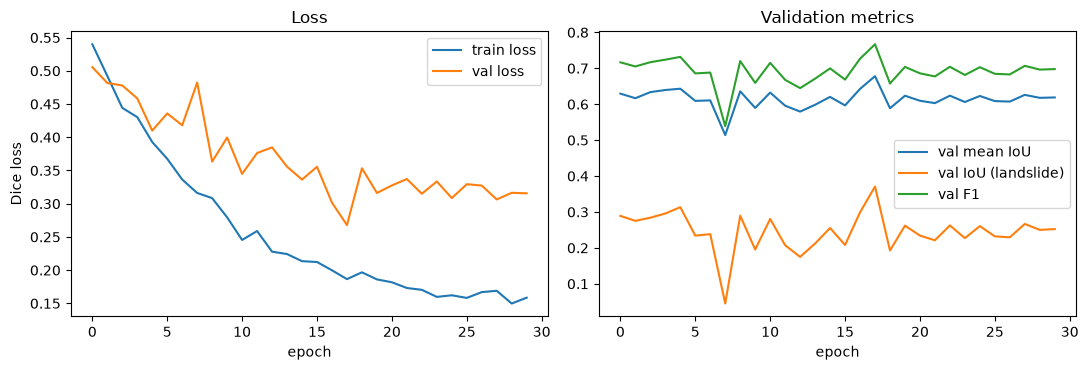

In [12]:
metrics_csv = Path(trainer.logger.log_dir) / "metrics.csv"
df = pd.read_csv(metrics_csv)

epoch_means = df.groupby("epoch").mean(numeric_only=True)   # collapse step-level rows per epoch

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(epoch_means.index, epoch_means["train/loss"], label="train loss")
axes[0].plot(epoch_means.index, epoch_means["val/loss"], label="val loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("Dice loss"); axes[0].legend(); axes[0].set_title("Loss")

axes[1].plot(epoch_means.index, epoch_means["val/mIoU"], label="val mean IoU")
axes[1].plot(epoch_means.index, epoch_means["val/IoU_1"], label="val IoU (landslide)")
axes[1].plot(epoch_means.index, epoch_means["val/F1_Score"], label="val F1")
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].set_title("Validation metrics")

fig.tight_layout()
fig.savefig(OUT_DIR / "training_curves.png", dpi=120)
plt.show()


### Validation metrics table

`trainer.validate` re-runs the validation split with the **best** checkpoint (not the last one) and returns the logged metrics, which we tidy into a table. Read it with the class imbalance in mind: `Pixel_Accuracy` and `IoU_0` (background) are inflated by the easy majority class — the honest rows are **`IoU_1`** (landslide-class IoU) and **`mIoU`** (the average of both).


In [13]:
val_results = trainer.validate(task, datamodule=datamodule, ckpt_path="best")

pd.DataFrame([
    {"metric": k.replace("val/", ""), "value": round(v, 4)}
    for k, v in val_results[0].items()
]).set_index("metric")


Restoring states from the checkpoint path at /media/volume/data_2T/bdec_pipeline/prithvi-landslide-workshop/checkpoints/prithvi300-landslide-epoch=17.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loaded model weights from the checkpoint at /media/volume/data_2T/bdec_pipeline/prithvi-landslide-workshop/checkpoints/prithvi300-landslide-epoch=17.ckpt


/home/exouser/miniconda3/envs/landslide/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


/home/exouser/miniconda3/envs/landslide/lib/python3.11/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       val/Accuracy        │    0.7467870116233826     │
│     val/Boundary_mIoU     │    0.2937931716442108     │
│   val/Class_Accuracy_0    │    0.9939450025558472     │
│   val/Class_Accuracy_1    │    0.49962905049324036    │
│       val/F1_Score        │    0.7668007612228394     │
│         val/IoU_0         │    0.9853540658950806     │
│         val/IoU_1         │    0.3707817792892456     │
│    val/Pixel_Accuracy     │    0.9854793548583984     │
│         val/loss          │    0.26776763796806335    │
│         val/mIoU          │    0.6780679225921631     │
│      val/mIoU_Micro       │    0.9713743925094604     │
└───────────────────────────┴───────────────────────────┘

,value
metric,
loss,0.2678
Accuracy,0.7468
Boundary_mIoU,0.2938
Class_Accuracy_0,0.9939
Class_Accuracy_1,0.4996
F1_Score,0.7668
IoU_0,0.9854
IoU_1,0.3708
Pixel_Accuracy,0.9855


### Qualitative check: predictions vs. ground truth

Metrics summarize; images convince. We run the fine-tuned model on the four validation patches with the *largest landslide coverage* (so there is something to see) and compare prediction to ground truth. Note what the model gets right (large, fresh scars) and where it struggles (thin runout tails, patch borders).

Here we do inference "by hand" (normalize → forward → argmax) — Part 2 does this in detail, so treat this cell as a preview.


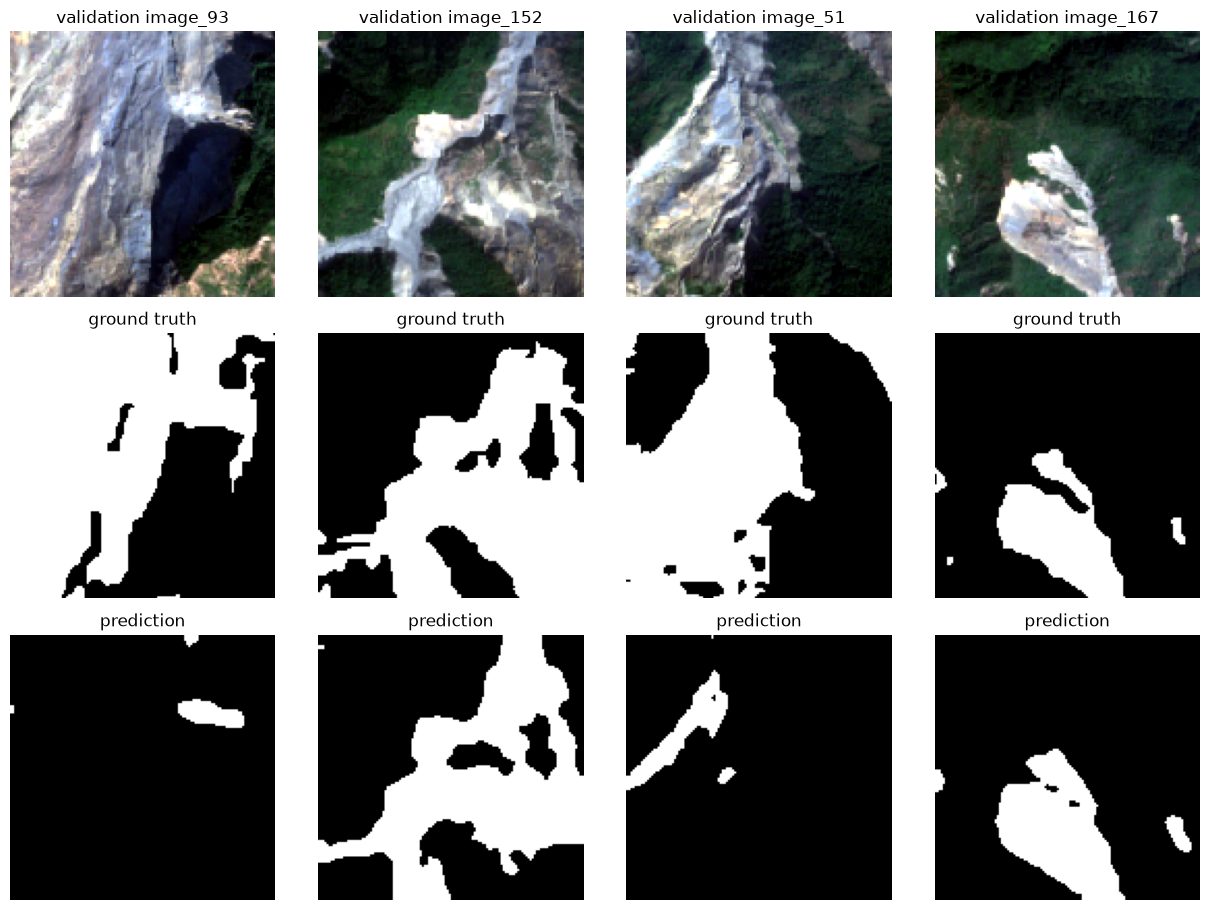

In [14]:
task_device = "cuda" if torch.cuda.is_available() else "cpu"
model = task.model.eval().to(task_device)

means = torch.tensor([MEANS[b] for b in BANDS]).view(1, -1, 1, 1)
stds  = torch.tensor([STDS[b]  for b in BANDS]).view(1, -1, 1, 1)
BAND_IDX = [1, 2, 3, 7, 10, 11]   # positions of our 6 bands within the 14-channel stack

# pick the validation patches with the largest landslide coverage
val_masks = sorted((DATA_DIR / "annotations" / "validation").glob("mask_*.h5"))
val_cover = []
for mf in val_masks:
    with h5py.File(mf) as f:
        val_cover.append(float(np.array(f["mask"]).mean()))
val_ids = [int(val_masks[i].stem.split("_")[1]) for i in np.argsort(val_cover)[::-1][:4]]

fig, axes = plt.subplots(3, 4, figsize=(12.5, 9.2))
for col, idx in enumerate(val_ids):
    img14, gt = load_sample("validation", idx)
    x = torch.from_numpy(img14[:, :, BAND_IDX]).float().permute(2, 0, 1).unsqueeze(0)
    x = (x - means) / stds                      # same per-band normalization as training
    with torch.no_grad():
        logits = model(x.to(task_device)).output
    pred = logits.argmax(dim=1).squeeze().cpu().numpy()

    axes[0, col].imshow(rgb_composite(img14)); axes[0, col].set_title(f"validation image_{idx}")
    axes[1, col].imshow(gt, cmap="gray");      axes[1, col].set_title("ground truth")
    axes[2, col].imshow(pred, cmap="gray");    axes[2, col].set_title("prediction")
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT_DIR / "val_predictions.png", dpi=120)
plt.show()


---
## Section 8. Knobs to turn *(≈5 min)*

### 🎯 Objective
Know what to change — and what to expect — when you adapt this pipeline.

| Knob | Where | Effect |
|------|-------|--------|
| **Learning rate** (`LR`) | Section 6 | The single most sensitive knob. 10× too high destroys the pretrained features (loss spikes, IoU collapses); 10× too low looks stable but underfits. We use 3e-5; try 1e-5–1e-4 and watch how the validation curve's shape changes. |
| **Augmentation** (`train_transform`) | Section 4 | Flips/rotations are free regularization on orientation-free targets. Remove them to watch overfitting arrive earlier; add radiometric jitter (e.g., `A.GaussNoise`) with care — it changes the spectra the model sees. |
| **Frozen backbone** (`freeze_backbone=True`) | task args | Trains only the ~20M-parameter decoder: ~2–3× faster per epoch, much less memory, and a good baseline for *how much* the labels teach vs. what pretraining already knew. Expect a few IoU points lower than end-to-end fine-tuning on this dataset. |
| **Epochs** (`NUM_EPOCHS`) | Section 6 | Validation IoU usually plateaus well before 30 epochs; the checkpoint callback already keeps the best epoch, so longer mostly costs time. Remember to keep `T_max` = epochs. |
| **Decoder choice** (`decoder=`) | model args | `FCNDecoder` is simpler/faster, `UperNetDecoder` is heavier; UNet is a solid middle ground. The decoder matters less than the backbone and LR. |
| **Batch size** | datamodule | Mostly a memory/VRAM knob. If you shrink it (small GPU), shrink the LR a little too. |
| **Loss** (`loss=`) | task args | Try `ce` (cross-entropy) to *see* the imbalance problem, or `focal`. With `ce` you can add `class_weights`. |
| **Backbone size** | `prithvi_eo_v2_100` / `_600` | Smaller = faster, a bit less accurate; 600M needs serious VRAM. Good scaling-law discussion. |
| **Extra channels** (slope/DEM) | advanced | TerraTorch can extend the patch embedding to extra input channels (new weights are trained from scratch). Topography is highly predictive for landslides — a great mini-project. |

> 🧪 **Suggested exercise:** duplicate the training cell with `freeze_backbone=True`, run 10 epochs, and compare the two validation IoU curves.
